# 07 · Customer experience
Questions 12–15: complaint volumes, resolution times, links to churn, and problem areas.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

In [2]:
pd.merge(o('q16_complaints_by_category'), o('q17_resolution_time').drop(columns='complaints'), on='complaint_category')

,complaint_category,complaints,share_pct,per_1000_subscriber_months,avg_days_to_resolve,median_days,p90_days,unresolved_or_escalated_pct
0,Network coverage,2332,22.10,3.87,12.80,10.00,27.00,29.80
1,Data speed,2191,20.80,3.63,7.60,6.00,15.00,19.40
2,Billing,1764,16.70,2.93,2.50,2.00,5.00,6.50
3,Mobile money,1570,14.90,2.60,5.50,5.00,11.00,7.80
4,Customer service,1476,14.00,2.45,3.40,3.00,6.00,7.20
5,SIM & device,1226,11.60,2.03,2.50,2.00,5.00,4.70


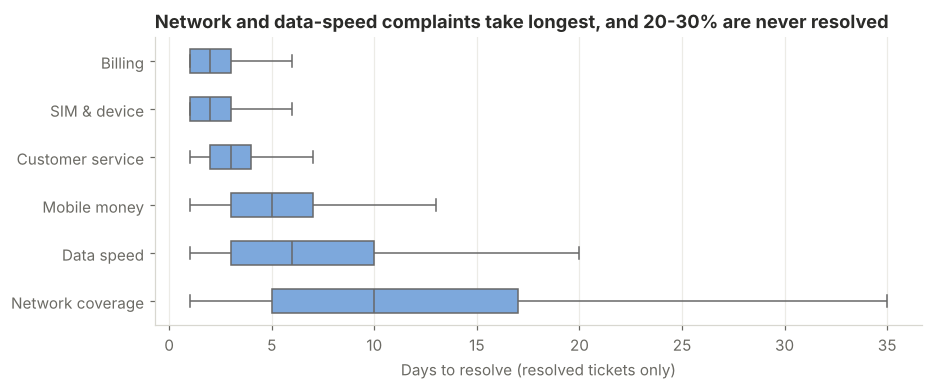

In [3]:
cp = query(engine, "SELECT complaint_category, resolution_date - complaint_date AS days FROM telco.complaints WHERE resolution_date IS NOT NULL")
order = cp.groupby("complaint_category").days.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.4))
sns.boxplot(data=cp, y="complaint_category", x="days", order=order, color=an.SEQ_BLUES[2], showfliers=False, ax=ax, width=.5)
ax.set_xlabel("Days to resolve (resolved tickets only)"); ax.set_ylabel(""); ax.set_title("Network and data-speed complaints take longest, and 20-30% are never resolved")
an.save(fig, "resolution_time_by_category");

,value_tier,complaint_experience,customers,churned,churned_pct
0,NaN,a) No complaint,15079,2988,19.80
1,NaN,b) Resolved within 7 days,1042,141,13.50
2,NaN,c) Resolved after 7+ days,351,41,11.70
3,NaN,d) Unresolved or escalated,233,58,24.90
4,Higher value (Platinum/Gold),a) No complaint,4135,534,12.90
5,Higher value (Platinum/Gold),b) Resolved within 7 days,334,31,9.30
6,Higher value (Platinum/Gold),c) Resolved after 7+ days,117,7,6.00
7,Higher value (Platinum/Gold),d) Unresolved or escalated,73,14,19.20
8,Lower value (Silver/Bronze),a) No complaint,10944,2454,22.40
9,Lower value (Silver/Bronze),b) Resolved within 7 days,708,110,15.50


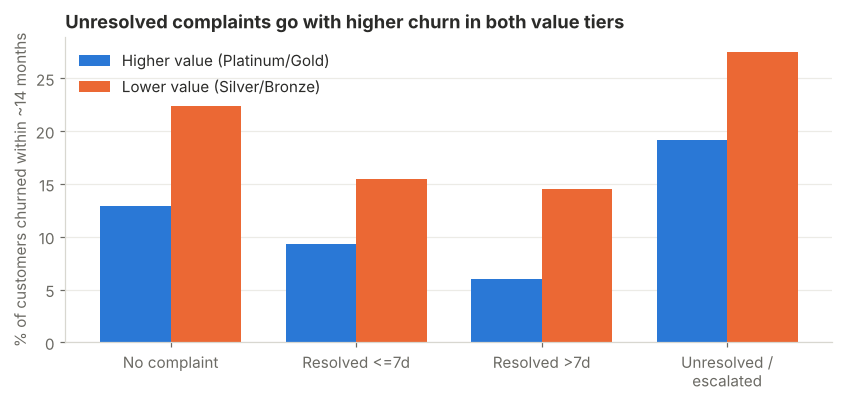

In [4]:
q = o("q18_complaints_and_churn").dropna(subset=["value_tier"])
fig, ax = plt.subplots(figsize=(9, 3.6))
tiers = q.value_tier.unique(); x = np.arange(4); w = .38
for i, (t, col) in enumerate(zip(tiers, [an.PRIMARY, an.HIGHLIGHT])):
    d = q[q.value_tier == t].sort_values("complaint_experience")
    ax.bar(x + (i - .5) * w, d.churned_pct, w, color=col, label=t)
ax.set_xticks(x, ["No complaint", "Resolved <=7d", "Resolved >7d", "Unresolved /\nescalated"])
ax.set_ylabel("% of customers churned within ~14 months"); ax.legend(); ax.grid(axis="x", visible=False)
ax.set_title("Unresolved complaints go with higher churn in both value tiers")
an.save(fig, "complaints_vs_churn"); o("q18_complaints_and_churn")

**How to read this (question 14).** Within each value tier, customers whose complaint was **never resolved** churned at about 1.2–1.5× the rate of customers who didn't complain, and at nearly twice the rate of customers whose complaint *was* resolved.

Two cautions:
- *Confounding:* complainers skew towards higher-value customers, who churn less anyway, so the unsplit row understates the gap. That is why the analysis is split by tier.
- *Exposure:* customers who stay longer have more months in which to complain. That partly explains why "resolved" complainers churn *less* than non-complainers.

This shows **association**, not proof of cause. A controlled test, such as prioritised resolution for a random half of open tickets, would establish the effect.

,county,complaints,per_1000_subscriber_months,network_and_speed_per_1000,unresolved_pct
0,Garissa,724,28.50,15.63,17.50
1,Kilifi,925,27.32,14.97,16.10
2,Turkana,711,26.89,14.87,16.30
3,Unknown,318,17.63,7.93,11.90
4,Machakos,692,16.57,6.42,13.90
5,Nakuru,784,16.29,5.88,14.20
6,Nyeri,474,16.20,6.67,18.10
7,Kiambu,898,16.14,6.41,13.80
8,Uasin Gishu,557,16.02,6.21,13.30
9,Mombasa,948,15.98,6.36,14.90


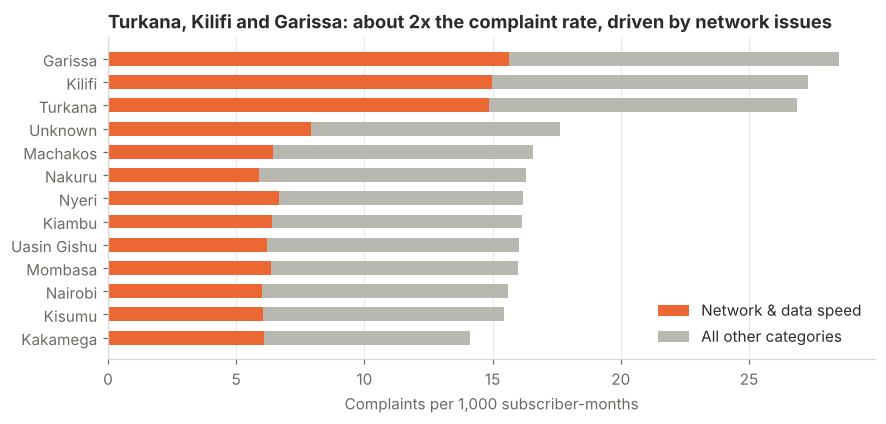

In [5]:
c = o("q19_complaints_by_county")
fig, ax = plt.subplots(figsize=(9, 3.8))
c = c.sort_values("per_1000_subscriber_months")
ax.barh(c.county, c.network_and_speed_per_1000, color=an.HIGHLIGHT, height=.6, label="Network & data speed")
ax.barh(c.county, c.per_1000_subscriber_months - c.network_and_speed_per_1000, left=c.network_and_speed_per_1000, color=an.CONTEXT, height=.6, label="All other categories")
ax.set_xlabel("Complaints per 1,000 subscriber-months"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Turkana, Kilifi and Garissa: about 2x the complaint rate, driven by network issues")
an.save(fig, "complaints_by_county"); o("q19_complaints_by_county")

In [6]:
o('q20_complaints_by_segment')

,value_segment,customer_type,customers,pct_ever_complained,complaints_per_1000_customer_months,unresolved_share_pct
0,Bronze (bottom 40%),Postpaid,561,29.10,15.70,16.80
1,Bronze (bottom 40%),Prepaid,10663,25.50,15.90,13.90
2,Gold (next 20%),Postpaid,337,27.90,17.50,15.60
3,Gold (next 20%),Prepaid,5276,28.70,17.30,14.90
4,Platinum (top 10%),Postpaid,2028,45.90,27.00,14.50
5,Platinum (top 10%),Prepaid,779,28.10,19.20,11.20
6,Silver (next 30%),Postpaid,429,34.00,17.10,14.30
7,Silver (next 30%),Prepaid,7989,31.10,17.00,14.80
8,Unsegmented (too new),Postpaid,48,2.10,20.80,0.00
9,Unsegmented (too new),Prepaid,386,2.80,28.50,27.30
